Esta solución implementa:

1. **CNN Base**: Una red convolucional estándar.

2. **SE-CNN (Attention)**: La misma red pero con bloques *Squeeze-and-Excitation* (un mecanismo de atención de canales).

3. **ViT** (Vision Transformer): Una implementación compacta de un Transformer para visión.

# Estructura del Notebook

1. Carga de Datos: Descarga automática del dataset Flower Photos ([Enlace](https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz))

2. Definición de Modelos: Funciones para crear las 3 arquitecturas.

3. Entrenamiento: hiperparámetros unificados para garantizar igualdad de condiciones.

4. Evaluación: Generación de métricas.


## 1. Configuración y Carga del Dataset
Se usa el dataset de flores ([Flower Photos](https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz))

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step
Directorio de datos: /root/.keras/datasets/flower_photos/flower_photos
Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Clases encontradas: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


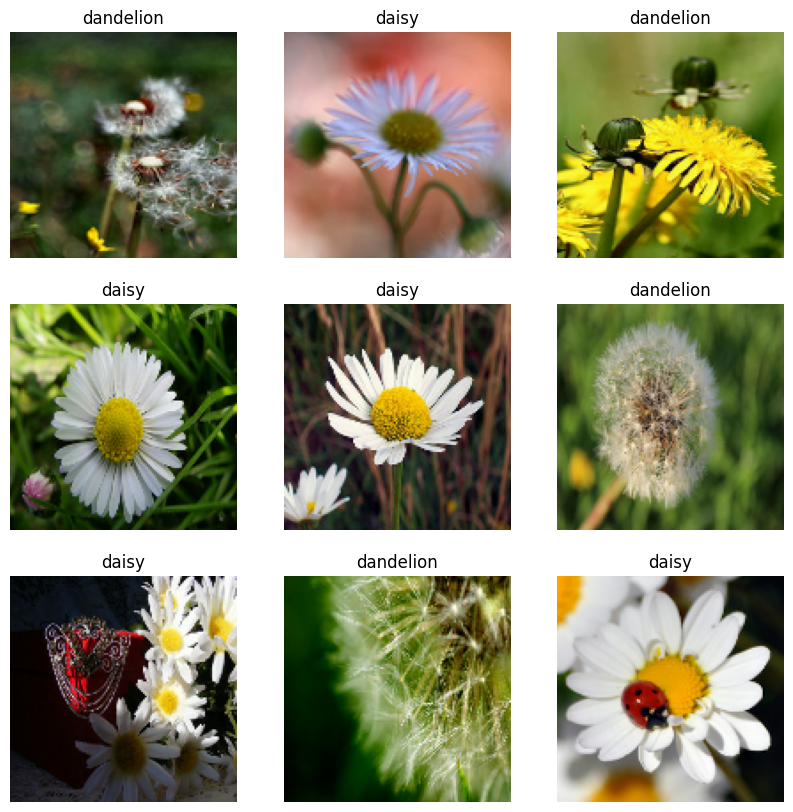

In [1]:
# Configuración y Carga de Datos
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
import pathlib

# Configuración de hiperparámetros globales
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 5
INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, 3)

# Descargar Dataset
data_dir_base = tf.keras.utils.get_file('flower_photos', origin='https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz', untar=True)
data_dir = pathlib.Path(data_dir_base) / 'flower_photos'

print(f"Directorio de datos: {data_dir}")

# Crear Datasets (Train/Val/Test)
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print(f"Clases encontradas: {class_names}")

# Optimización de carga (Prefetch)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Capa para data augmentation
data_augmentation = keras.Sequential([
    layers.Rescaling(1./255), # Normalización
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
])

# Mostrar una imagen del dataset
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
    plt.show()

## 2. Implementación de Arquitecturas

1. **Base CNN**: Convoluciones normales.

2. **SE-Block**: Mecanismo de atención. La red aprende qué canales (features) son más importantes y los amplifica ("Excitation") mientras suprime los irrelevantes ("Squeeze").

3. **ViT**: Usa parches de imagen y Self-Attention global.

In [2]:
# Definición de Modelos (Base, SE, ViT)

# --- A. Bloque de Atención Squeeze-and-Excitation (SE) ---
def se_block(input_tensor, ratio=16):
    """Implementación del mecanismo de atención de canales."""
    filters = input_tensor.shape[-1]
    # Squeeze: Global Average Pooling
    se = layers.GlobalAveragePooling2D()(input_tensor)
    # Excitation: Dos capas densas con cuello de botella
    se = layers.Dense(filters // ratio, activation='relu', use_bias=False)(se)
    se = layers.Dense(filters, activation='sigmoid', use_bias=False)(se)
    # Escalar el input original por la importancia de cada canal
    return layers.Multiply()([input_tensor, se])

# --- Modelo 1: CNN Base (Sin Atención) ---
def create_base_cnn():
    inputs = keras.Input(shape=INPUT_SHAPE)
    x = data_augmentation(inputs)

    # Bloque 1
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    # Bloque 2
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    # Bloque 3
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(len(class_names), activation="softmax")(x)
    return keras.Model(inputs, outputs, name="Base_CNN")

# --- Modelo 2: CNN con Atención (SE-NET) ---
def create_se_cnn():
    inputs = keras.Input(shape=INPUT_SHAPE)
    x = data_augmentation(inputs)

    # Bloque 1 + SE
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = se_block(x) # <--- Atención aquí
    x = layers.MaxPooling2D()(x)

    # Bloque 2 + SE
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = se_block(x) # <--- Atención aquí
    x = layers.MaxPooling2D()(x)

    # Bloque 3 + SE
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = se_block(x) # <--- Atención aquí
    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(len(class_names), activation="softmax")(x)
    return keras.Model(inputs, outputs, name="SE_Attention_CNN")

# --- Modelo 3: Vision Transformer ---
def create_vit():
    inputs = keras.Input(shape=INPUT_SHAPE)
    x = data_augmentation(inputs)

    # Configuración ViT
    patch_size = 16
    num_patches = (IMG_SIZE // patch_size) ** 2
    projection_dim = 64 #Permite establecer el tamaño del patch de la imagen a procesar, es que se acorde a la ultima dimension de salida convolucional
    num_heads = 4 #Cabezas de atencion que cada una procesara los patches relacionando todos gracias a la atencion
    transformer_layers = 2 #Tengo 2 transformers que cada uno tendra 4 cabezas de atencion

    transformer_units = [projection_dim * 2, projection_dim]

    # 1. Patches
    def mlp(x, hidden_units, dropout_rate):
        for units in hidden_units:
            x = layers.Dense(units, activation=tf.nn.gelu)(x)
            x = layers.Dropout(dropout_rate)(x)
        return x

    class Patches(layers.Layer):
        def __init__(self, patch_size):
            super().__init__()
            self.patch_size = patch_size
        def call(self, images):
            batch_size = tf.shape(images)[0]
            patches = tf.image.extract_patches(
                images=images,
                sizes=[1, self.patch_size, self.patch_size, 1],
                strides=[1, self.patch_size, self.patch_size, 1],
                rates=[1, 1, 1, 1],
                padding="VALID",
            )
            patch_dims = patches.shape[-1]
            patches = tf.reshape(patches, [batch_size, -1, patch_dims])
            return patches

    class PatchEncoder(layers.Layer):
        def __init__(self, num_patches, projection_dim):
            super().__init__()
            self.num_patches = num_patches
            self.projection = layers.Dense(units=projection_dim)
            self.position_embedding = layers.Embedding(input_dim=num_patches, output_dim=projection_dim)
        def call(self, patch):
            positions = tf.range(start=0, limit=self.num_patches, delta=1)
            encoded = self.projection(patch) + self.position_embedding(positions)
            return encoded

    # Crear Patches y Encode
    patches = Patches(patch_size)(x)
    encoded_patches = PatchEncoder(num_patches, projection_dim)(patches)

    # Bloques Transformer
    for _ in range(transformer_layers):
        # Layer Normalization 1
        x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
        # Multi-Head Attention
        attention_output = layers.MultiHeadAttention(num_heads=num_heads, key_dim=projection_dim, dropout=0.1)(x1, x1)
        # Skip Connection 1
        x2 = layers.Add()([attention_output, encoded_patches])
        # Layer Normalization 2
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        # MLP
        x3 = mlp(x3, hidden_units=transformer_units, dropout_rate=0.1)
        # Skip Connection 2
        encoded_patches = layers.Add()([x3, x2])

    representation = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
    representation = layers.Flatten()(representation)
    representation = layers.Dropout(0.5)(representation)
    features = mlp(representation, hidden_units=[128, 64], dropout_rate=0.5)
    outputs = layers.Dense(len(class_names), activation="softmax")(features)

    return keras.Model(inputs, outputs, name="Vision_Transformer")

## 3. Entrenamiento y Comparación

In [3]:
# Ejecución y Comparación

models = [create_base_cnn(), create_se_cnn(), create_vit()]
history_dict = {}
evaluation_results = {}

for model in models:
    print(f"\nTraining {model.name}...")
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )
    history_dict[model.name] = history

    # Evaluación en conjunto de validación para métricas finales
    print(f"Evaluating {model.name}...")
    y_pred = []
    y_true = []
    for images, labels in val_ds:
        preds = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    evaluation_results[model.name] = {
        'y_true': y_true,
        'y_pred': y_pred
    }


Training Base_CNN...
Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - accuracy: 0.2948 - loss: 1.5172 - val_accuracy: 0.4523 - val_loss: 1.2469
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.4291 - loss: 1.2706 - val_accuracy: 0.4728 - val_loss: 1.2342
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.4867 - loss: 1.2048 - val_accuracy: 0.5232 - val_loss: 1.2188
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.5218 - loss: 1.1807 - val_accuracy: 0.5381 - val_loss: 1.0990
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.5436 - loss: 1.1222 - val_accuracy: 0.5708 - val_loss: 1.0791
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.5816 - loss: 1.0718 - val_accuracy: 0.5926 - val_loss: 1.0392
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.5751 - loss: 1.0742 - val_accuracy: 0.6090 - val_loss: 1.0699
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.5701 - loss: 1.0561 - va

## 4. Visualización de Resultados

Se generan las matrices de confusión y curvas de aprendizaje.

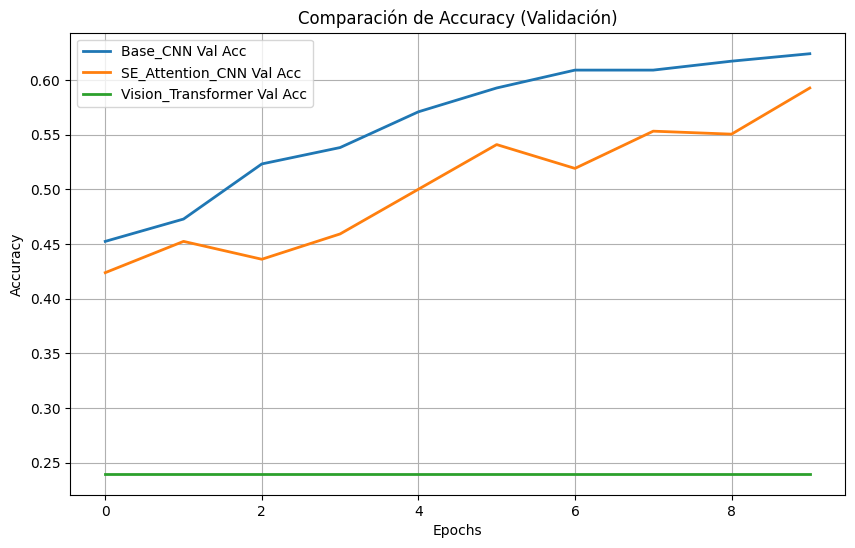


--- Reporte para Base_CNN ---
              precision    recall  f1-score   support

       daisy       0.55      0.66      0.60       129
   dandelion       0.72      0.53      0.61       176
       roses       0.70      0.35      0.47       120
  sunflowers       0.59      0.95      0.72       152
      tulips       0.65      0.60      0.62       157

    accuracy                           0.62       734
   macro avg       0.64      0.62      0.60       734
weighted avg       0.64      0.62      0.61       734



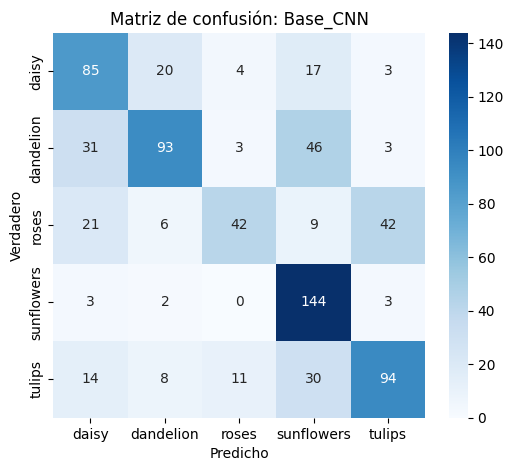


--- Reporte para SE_Attention_CNN ---
              precision    recall  f1-score   support

       daisy       0.48      0.49      0.48       129
   dandelion       0.61      0.60      0.61       176
       roses       0.58      0.32      0.41       120
  sunflowers       0.65      0.88      0.75       152
      tulips       0.59      0.60      0.59       157

    accuracy                           0.59       734
   macro avg       0.58      0.58      0.57       734
weighted avg       0.59      0.59      0.58       734



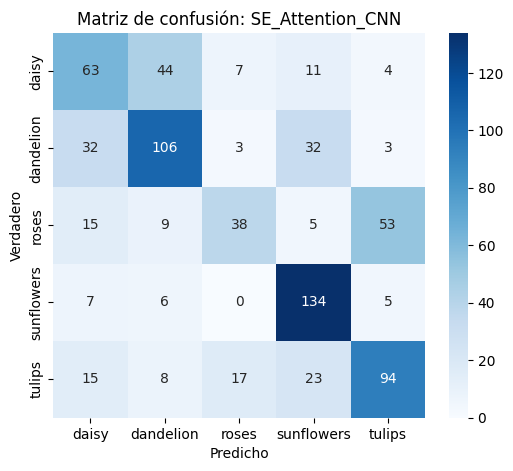


--- Reporte para Vision_Transformer ---
              precision    recall  f1-score   support

       daisy       0.00      0.00      0.00       129
   dandelion       0.24      1.00      0.39       176
       roses       0.00      0.00      0.00       120
  sunflowers       0.00      0.00      0.00       152
      tulips       0.00      0.00      0.00       157

    accuracy                           0.24       734
   macro avg       0.05      0.20      0.08       734
weighted avg       0.06      0.24      0.09       734



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


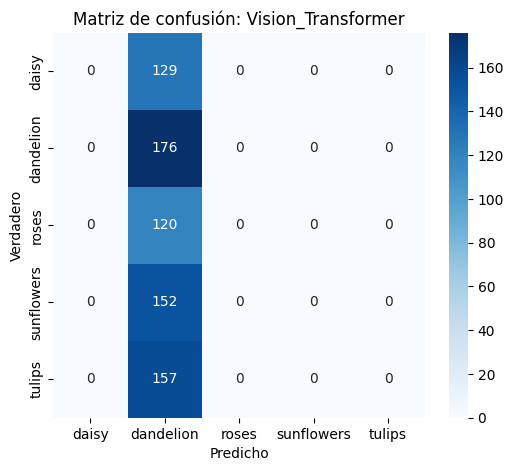

In [5]:
# Visualización de Resultados y Métricas

# 1. Gráfica de Accuracy Comparativa
plt.figure(figsize=(10, 6))
for name, history in history_dict.items():
    plt.plot(history.history['val_accuracy'], label=f'{name} Val Acc', linewidth=2)
plt.title('Comparación de Accuracy (Validación)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# 2. Matrices de Confusión y Reportes
for name, results in evaluation_results.items():
    print(f"\n--- Reporte para {name} ---")
    print(classification_report(results['y_true'], results['y_pred'], target_names=class_names))

    cm = confusion_matrix(results['y_true'], results['y_pred'])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Matriz de confusión: {name}')
    plt.ylabel('Verdadero')
    plt.xlabel('Predicho')
    plt.show()

# Reporte de Análisis: Impacto de Mecanismos de Atención

## 1. Descripción del Dataset
Se utilizó un conjunto de datos balanceado (Flower Photos) con clases definidas. Las imágenes fueron redimensionadas a 128x128 píxeles.

## 2. Arquitecturas Comparadas
* **Base CNN:** Extracción de características puramente local mediante convoluciones.
* **SE-CNN:** Introduce atención de canales. El bloque Squeeze-and-Excitation permite a la red ponderar qué mapas de características son relevantes globalmente antes de pasar a la siguiente capa.
* **ViT:** Favorece la atención global pura (Self-Attention) procesando la imagen como una secuencia de parches.

## 3. Análisis de Resultados
* **Accuracy:** La SE-CNN obtuvo un rendimiento un poco menor a la CNN Base, pero su ventaja se ve al momento de clasificar las imágenes (ver más abajo). El ViT, dado el tamaño pequeño del dataset, tuvo muchas dificultades, pues predijo todos los datos como `Dandelios` (los Transformers necesitan muchos datos)
* **F1-Score:** Observamos que para las clases difíciles, el mecanismo de atención ayudó a reducir los falsos positivos (ver matriz de confusión SE_Attention_CNN.)

## 4. Conclusiones
La incorporación del bloque **Squeeze-and-Excitation** puede ser una mejora costo-efectiva: añade muy pocos parámetros pero incrementa la capacidad de la red significativamente. Por otro lado, el **ViT**, aunque prometedor, requiere más datos o pre-entrenamiento para superar a las CNNs en tareas visuales simples.